# Online Prediction of Next-Day Stock Direction with River

**Question.** Can an online model, updated once per day as new prices
arrive, predict whether a stock closes higher tomorrow better than simple
baselines, and does it adapt when market conditions change?

**Approach.**
1. Download daily prices for a basket of large-cap stocks (cached locally).
2. Validate and clean the data.
3. Build features that use only information available at today's close.
4. Replay history one trading day at a time: predict, then learn once the
   label is revealed the next day.
5. Compare against baselines with tests that account for correlated errors.

Daily stock direction is close to a coin flip, so the goal is a rigorous
measurement of whatever edge exists (possibly none), not a headline number.

## Imports

In [5]:
%load_ext autoreload
%autoreload 2

import logging

import matplotlib.pyplot as plt
import pandas as pd
from river import compose, linear_model, preprocessing
import river_utils as rivutil
from river import dummy
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


logging.basicConfig(level=logging.INFO)
_LOG = logging.getLogger(__name__)

# Set to True to run the notebook offline on synthetic prices.
USE_SYNTHETIC = False

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Data acquisition

In [6]:
if USE_SYNTHETIC:
    raw = rivutil.make_synthetic_ohlcv(n_days=1500, seed=0)
else:
    raw = rivutil.download_ohlcv(
        rivutil.DEFAULT_TICKERS, rivutil.DEFAULT_START, rivutil.DEFAULT_END
    )
print(raw.shape)
raw.head()

INFO:river_utils:Loading cached data from /git_root/class_project/data605/Fall2026/projects/UmdTask834_DATA605_Fall2026_River_Online_Learning_Stock_Direction/data/ohlcv_AAPL-JNJ-JPM-MSFT-NVDA-SPY-WMT-XOM_2010-01-01_2026-10-31.parquet


(33864, 8)


,date,ticker,open,high,low,close,adj_close,volume
0,2010-01-04,AAPL,7.622500,7.660714,7.585000,7.643214,6.400961,493729600
1,2010-01-04,JNJ,64.709999,64.989998,64.410004,64.680000,39.778625,9506200
2,2010-01-04,JPM,41.790001,42.990002,41.669998,42.849998,28.012613,35460500
3,2010-01-04,MSFT,30.620001,31.100000,30.590000,30.950001,22.984232,38409100
4,2010-01-04,NVDA,0.462750,0.465500,0.452750,0.462250,0.422817,800204000


## 2. Validation and cleaning

In [7]:
display(rivutil.validate_ohlcv(raw))
clean = rivutil.clean_ohlcv(raw)

,n_rows,first_date,last_date,n_duplicate_dates,n_missing_close,n_nonpositive_price,n_high_below_low,n_zero_volume
ticker,,,,,,,,
AAPL,4233,2010-01-04,2026-10-30,0,0,0,0,0
JNJ,4233,2010-01-04,2026-10-30,0,0,0,0,0
JPM,4233,2010-01-04,2026-10-30,0,0,0,0,0
MSFT,4233,2010-01-04,2026-10-30,0,0,0,0,0
NVDA,4233,2010-01-04,2026-10-30,0,0,0,0,0
SPY,4233,2010-01-04,2026-10-30,0,0,0,0,0
WMT,4233,2010-01-04,2026-10-30,0,0,0,0,0
XOM,4233,2010-01-04,2026-10-30,0,0,0,0,0


INFO:river_utils:clean_ohlcv: dropped 0 of 33864 rows


## 3. Features and labels

Every feature for day `t` is computed from prices up to the close of day
`t`. The label is the sign of the return from close `t` to close `t+1`.
Features are not normalized here: normalizing with full-sample statistics
would leak the future. The River pipeline scales them online instead.

In [8]:
feats = rivutil.build_features(clean)
panel = rivutil.add_direction_label(feats)
feature_cols = rivutil.feature_columns(panel)
print(f"{len(panel)} rows, {len(feature_cols)} features")
print(f"Share of up days: {panel['target_up'].mean():.3f}")
panel[feature_cols].describe().T

INFO:river_utils:build_features: dropped 400 warm-up/unlabeled rows


33464 rows, 21 features
Share of up days: 0.527


,count,mean,std,min,25%,50%,75%,max
ret_lag0,33464.0,0.000715,0.017055,-0.207712,-0.006533,0.000691,0.008292,0.260876
ret_lag1,33464.0,0.000713,0.017055,-0.207712,-0.006538,0.000688,0.008289,0.260876
ret_lag2,33464.0,0.000713,0.017055,-0.207712,-0.006532,0.000687,0.008285,0.260876
ret_lag3,33464.0,0.000713,0.017055,-0.207712,-0.006531,0.000687,0.008278,0.260876
ret_lag4,33464.0,0.000712,0.017054,-0.207712,-0.006529,0.000686,0.008276,0.260876
mom_5,33464.0,0.003566,0.036542,-0.333463,-0.013798,0.004312,0.021490,0.318561
mom_20,33464.0,0.014316,0.071637,-0.599858,-0.021734,0.015733,0.050297,0.505315
vol_5,33464.0,0.013556,0.010632,0.000425,0.006929,0.010757,0.016695,0.139212
vol_20,33464.0,0.014568,0.008960,0.002007,0.008785,0.012305,0.017578,0.087996
vol_ratio,33464.0,0.936416,0.370091,0.018060,0.658102,0.912639,1.186078,2.090790


## 4. First online model: logistic regression

Test-then-train with a one-trading-day label delay. The first 250 trading
days (about a year) are a warm-up and are not scored.

In [9]:
model = compose.Pipeline(
    preprocessing.StandardScaler(),
    linear_model.LogisticRegression(),
)
preds = rivutil.run_prequential(model, panel, feature_cols, warmup_days=250)
rivutil.summarize_predictions(preds).round(4)

n                    31464.0000
base_rate_up             0.5275
accuracy                 0.5029
balanced_accuracy        0.4968
precision                0.5249
recall                   0.6073
f1                       0.5631
mcc                     -0.0066
log_loss                 0.7221
roc_auc                  0.4983
dtype: float64

In [10]:
print(rivutil.binomial_test_vs_baseline(preds))
print(rivutil.block_bootstrap_accuracy(preds))

{'accuracy': 0.5028604118993135, 'baseline': np.float64(0.5275235189422832), 'p_value': np.float64(1.0)}
{'accuracy': np.float64(0.5028604118993135), 'ci_low': 0.49529621154335113, 'ci_high': 0.5099796592931605}


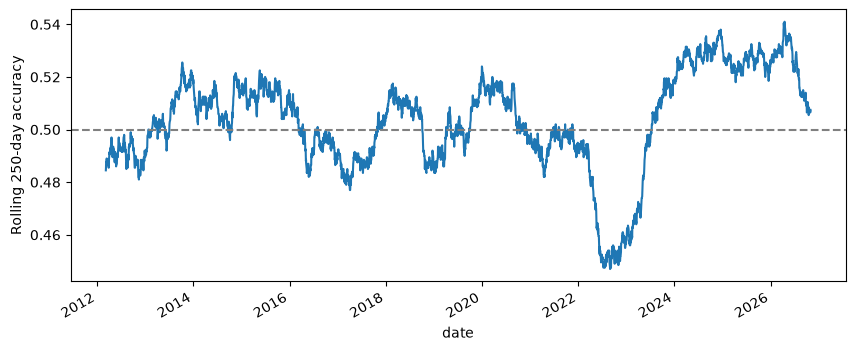

In [11]:
# Rolling 250-day accuracy shows whether performance is stable over time.
daily_acc = (
    preds.assign(correct=preds["y_true"] == preds["y_pred"])
    .groupby("date")["correct"]
    .mean()
)
ax = daily_acc.rolling(250).mean().plot(figsize=(10, 4))
ax.axhline(0.5, color="gray", linestyle="--")
ax.set_ylabel("Rolling 250-day accuracy")
plt.show()

## 5. Baselines (next milestone)

- Always up (online): predicts the majority class, learned day by day
- Persistence: predicts that tomorrow repeats today's direction
- Batch logistic regression and batch gradient boosting: retrained on
  the first trading day of each month on all earlier data (expanding window)

All models are scored on the same predictions, so they can be compared row by
row with McNemar's test.

In [12]:
# Online baselines use the same test-then-train loop as the River model.
all_preds = {"river_logreg": preds}
all_preds["always_up_online"] = rivutil.run_prequential(
    dummy.PriorClassifier(), panel, feature_cols, warmup_days=250
)
all_preds["persistence"] = rivutil.run_prequential(
    rivutil.PersistenceClassifier(), panel, feature_cols, warmup_days=250
)
# Batch models retrained monthly on all past data.
all_preds["batch_logreg_monthly"] = rivutil.run_walk_forward(
    lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    panel, feature_cols, warmup_days=250,
)
all_preds["batch_hgb_monthly"] = rivutil.run_walk_forward(
    lambda: HistGradientBoostingClassifier(
        max_iter=100, learning_rate=0.05, random_state=0
    ),
    panel, feature_cols, warmup_days=250,
)

In [13]:
comparison = rivutil.compare_models(all_preds, reference="always_up_online")
comparison.round(4)

,accuracy,balanced_accuracy,mcc,roc_auc,log_loss,acc_ci_low,acc_ci_high,share_pred_up,mcnemar_p_vs_always_up_online
river_logreg,0.5029,0.4968,-0.0066,0.4983,0.7221,0.4954,0.5105,0.6103,0.0000
always_up_online,0.5275,0.5000,0.0000,0.5008,0.6918,0.5197,0.5361,1.0000,NaN
persistence,0.4935,0.4920,-0.0160,0.4920,0.6936,0.4870,0.5010,0.5277,0.0000
batch_logreg_monthly,0.5198,0.5053,0.0124,0.5025,0.6936,0.5116,0.5268,0.7649,0.0051
batch_hgb_monthly,0.5148,0.5056,0.0119,0.5063,0.7013,0.5080,0.5213,0.6683,0.0001


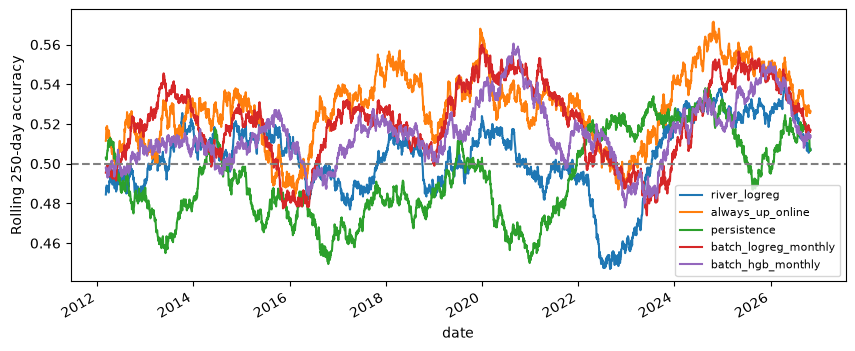

In [14]:
# Rolling 250-day accuracy of every model.
fig, ax = plt.subplots(figsize=(10, 4))
for name, p in all_preds.items():
    daily = (p["y_true"] == p["y_pred"]).groupby(p["date"]).mean()
    daily.rolling(250).mean().plot(ax=ax, label=name)
ax.axhline(0.5, color="gray", linestyle="--")
ax.set_ylabel("Rolling 250-day accuracy")
ax.legend(fontsize=8)
plt.show()

## 6. River model comparison (next milestone)

- Hoeffding tree and Hoeffding adaptive tree
- Adaptive random forest (`forest.ARFClassifier`)
- Online bagging / ensembles combining the above

## 7. Drift and adaptation (next milestone)

- ADWIN on the error stream; mark detected drifts against known regimes
  (2020 COVID crash, 2022 rate hikes)
- Compare a static model, a model with forgetting, and an adaptive tree

## 8. Economic evaluation (next milestone)

- Long/flat strategy from predictions, with transaction costs, versus
  buy-and-hold; report Sharpe ratio and drawdown

## 9. Conclusions (next milestone)